# Lab: Keyhole Surgery, Guided by a Camera

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LxViRaL-teaching/medical-robotics-2026/blob/main/week-4/robmed_visservo.ipynb)

In keyhole (minimally invasive) surgery the instruments enter the body through small incisions, each held open by a port called a **trocar**.
In this lab you control the S2RK, an open-source surgical robot from the Hefei University of Technology (HFUT), so that:

1. its instrument always stays in the trocar, without tearing the abdominal wall;
2. a camera on the instrument guides it until it points straight at a target on the liver, marked by a blue dot. This arrangement is called eye-in-hand (it is more common to use eye-to-hand in surgical settings)
3. it then advances the instrument until it touches the liver there, feeling the contact with a force sensor at the tip.

As extras, you will visit the other two dots (green, then yellow), and finally slide from dot to dot while keeping a gentle, controlled contact force on the liver.

This brings together the kinematics (joint coordinates, Jacobians), the control loops (you can include torque control and gravity compensation), and a first use of images as a sensor.

Besides this notebook there are these auxiliary files:

| File | What it is |
|---|---|
| `s2rk_robot.urdf`, `meshes/` | The robot, built from the S2RK authors' CAD model, with a camera on the instrument. |
| `rcm_coupling.csv` | How the joints of the arm must move together to pivot the instrument about the trocar (section 3). |
| `port_torus.obj` | The shape of the trocar port. |
| `human_liver.obj` | The liver, with three coloured dots on its surface. |
| `figures/` | The figures of this notebook. |
| `keyhole_utils.py` | Helpers to load the robot and the scene, take pictures, find the dots and draw plots. You do not need to edit it. |

First, let's check the environment and do the relevant imports:

In [2]:
import os, sys, time

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pybullet"], check=True)
    if not os.path.exists("medical-robotics-2026"):
        subprocess.run(["git", "clone", "-q", "https://github.com/LxViRaL-teaching/medical-robotics-2026.git"], check=True)
    os.chdir("medical-robotics-2026/week-4")

import numpy as np
import pybullet as p
import keyhole_utils as kh

DT = kh.DT   # time step of the simulation, and of our controller: 1/240 s

## 1. The scene

`kh.load_robot` loads the robot on a pedestal, with its base 0.5 m above the floor. `kh.add_scene` adds:

* the **trocar port**: a rigid ring around the instrument, at a known point, with a **force sensor**: `kh.port_force(robot, port)` gives the force of the instrument on the port. If the instrument only pivots and slides, it never touches the ring and the force is zero;
* the **liver**, below the trocar, with three coloured dots (yellow, green, blue) in a triangle on its surface. Its surface is soft: it gives a little when pressed.

The instrument has a **force/torque sensor at its tip**: `kh.tip_wrench(robot)` returns the force and the torque that the tip applies to whatever it touches, in the tip frame ($z$ along the instrument, pointing out of the tip). `force[2] > 0` means the tip is pushing forward. Like a real tip sensor, it only feels contacts on the last centimetre of the instrument.

`kh.add_patient` adds, only to help you picture the operation, a transparent patient lying on an operating table with the trocar on the belly. It does not touch the robot, and the camera sees through it. (Not added on Colab)

In [3]:
kh.connect()
robot = kh.load_robot()
scene = kh.add_scene(robot)
patient = kh.add_patient()
joints = kh.joint_indices(robot)     # PyBullet indices of j1..j6
port = scene["port"]
liver = scene["liver"]
max_forces = [30, 30, 30, 30, 30, 40]  # motor limits from the URDF [N m for j1..j5, N for j6]

kh.joint_summary(robot)
print("Trocar (RCM) at", kh.RCM_POSITION, "m")

0  j1  revolute   limits [-0.785, +0.785] rad  moves link: Link1
1  j2  revolute   limits [-0.785, +0.785] rad  moves link: Link2
2  j3  revolute   limits [-0.785, +0.785] rad  moves link: Link3
3  j4  revolute   limits [-0.785, +0.785] rad  moves link: Link4
4  j5  revolute   limits [-0.785, +0.785] rad  moves link: Link5
5  j6  prismatic  limits [-0.100, +0.100] m    moves link: Link6
Trocar (RCM) at [0.7235 0.     0.68  ] m


The robot has six joints. `j1` swings the whole arm sideways, `j2` to `j5` are the joints of its parallelogram arm, and `j6` slides the instrument along its axis (positive values push it in).
On the real robot the parallelogram is a closed mechanism. **In our simulation it is open: the six joints move independently.**

## 2. The remote centre of motion

![The remote centre of motion](figures/rcm_concept.png)

Once the instrument is inside the trocar, the trocar point must not move: the robot may only **rotate the instrument about it** and **slide it in and out**.
That point is the **remote centre of motion (RCM)**: "remote" because no joint of the robot is there, the arm creates the rotation from a distance.

We measure how well the robot respects it with the **RCM error**: the distance from the trocar point to the instrument axis, the line through the tool tip along the shaft.

We write `rcm_error(robot)` using `kh.link_pose(robot, "tool_tip_link")` and `kh.link_pose(robot, "instrument_axis_link")`: each returns a position and a rotation matrix, and the $z$ axis of `instrument_axis_link` points along the shaft. The distance is the difference between the projection on the shaft direction and the direction itself.

In [4]:
def rcm_error(robot):
    # Distance from the trocar to the instrument axis [m]
    tip_position, _ = kh.link_pose(robot, "tool_tip_link")
    _, axis_rotation = kh.link_pose(robot, "instrument_axis_link")
    shaft_direction = axis_rotation[:, 2]                   # unit vector along the shaft [-]

    tip_to_trocar = kh.RCM_POSITION - tip_position          # [m]
    along_shaft = np.dot(tip_to_trocar, shaft_direction) * shaft_direction
    across_shaft = tip_to_trocar - along_shaft              # part perpendicular to the shaft [m]
    return np.linalg.norm(across_shaft)


print(f"RCM error at HOME: {rcm_error(robot) * 1000:.2f} mm")

RCM error at HOME: 0.03 mm


What happens if we move just one joint of the parallelogram? We command `j2` to turn by 0.06 rad and back, with PyBullet's position control, and record the RCM error and the force measured on the trocar port.

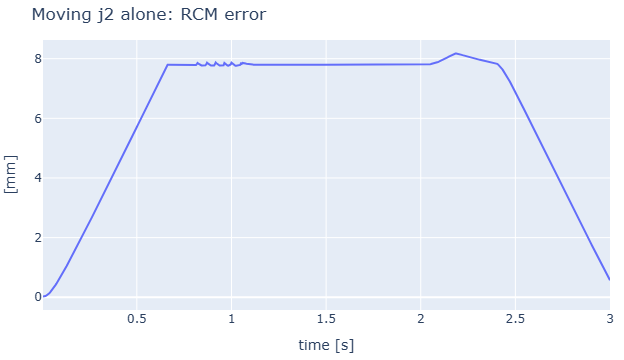

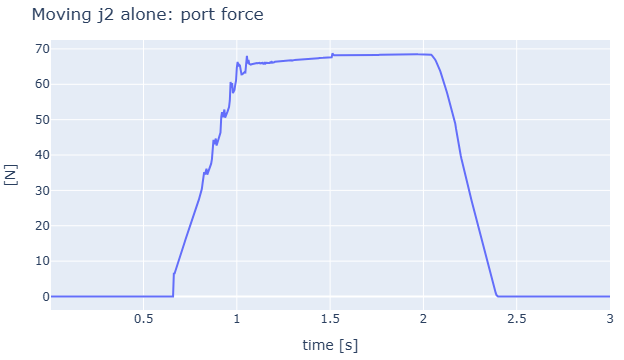

In [5]:
q_home = np.array(kh.HOME)                 # joint values [rad x5, m]

duration = 3.0           # [s]
j2_amplitude = 0.06      # [rad]
t = 0.0
time_log, rcm_log, force_log = [], [], []

while t < duration:
    # 1. SENSE: measure the RCM error and the force of the instrument on the trocar port
    error = rcm_error(robot)
    force = np.linalg.norm(kh.port_force(robot, port))

    # 2. CONTROL: j2 goes up to j2_amplitude in 1 s, stays there, and comes back in the last second
    if t < 1.0:
        j2_offset = j2_amplitude * t
    elif t < 2.0:
        j2_offset = j2_amplitude
    else:
        j2_offset = j2_amplitude * (duration - t)
    q_target = q_home.copy()
    q_target[1] = q_home[1] + j2_offset

    # 3. ACT: send the joint targets to the motors and let the world move for one time step
    p.setJointMotorControlArray(robot, joints, p.POSITION_CONTROL, targetPositions=q_target, forces=max_forces)
    p.stepSimulation()

    # 4. WAIT: let one time step of real time pass, so what you see runs at real speed
    time.sleep(DT)
    t = t + DT

    time_log.append(t)
    rcm_log.append(error * 1000)
    force_log.append(force)

kh.plot_series(time_log, {"RCM error [mm]": rcm_log}, ylabel="[mm]", title="Moving j2 alone: RCM error")
kh.plot_series(time_log, {"force on the port [N]": force_log}, ylabel="[N]", title="Moving j2 alone: port force")

The instrument moves sideways at the trocar until it hits the ring, and then pushes on it with tens of newtons.
In a real patient, that force is applied to the abdominal wall, and tears it. The joints must move **together**.

## 3. Moving the joints together: a reduced problem

![The three reduced coordinates](figures/rcm_reduced.png)

With the RCM fixed, the instrument keeps only three degrees of freedom:

| Reduced coordinate | Motion | Joints |
|---|---|---|
| swing $\psi$ | rotation about the horizontal $x$ axis through the RCM | `j1` alone (its axis passes through the RCM) |
| pitch $\varphi$ | rotation about the horizontal $y$ axis through the RCM | `j2`, `j3`, `j4`, `j5` together |
| insertion $d$ | translation along the instrument | `j6` alone |

Six joints, but only three independent coordinates: the RCM constraint **reduces** the problem from six to three degrees of freedom.
`j1` and `j6` already respect the RCM on their own. The difficult one is the pitch:

![The S2RK arm pivoting about the RCM](figures/rcm_robot.png)

For a pitch $\varphi$ we need joint values $(j_2, j_3, j_4, j_5)$ such that, in the side view:

1. the instrument axis passes through the RCM (no sideways offset);
2. the same point of the shaft stays at the RCM (pivoting, not sliding; sliding is the job of `j6`);
3. the instrument is turned by $\varphi$.

These are 3 equations for 4 unknowns, so there are many solutions. We chose the one with the **smallest joint motion**: starting at HOME, the pitch was increased in small steps, and at each step the joint velocities were computed with the pseudo-inverse of the Jacobian of these three constraints, exactly as in the differential kinematics you studied before.
The result is stored in `rcm_coupling.csv`, and `kh.parallelogram_joints(pitch)` reads it:

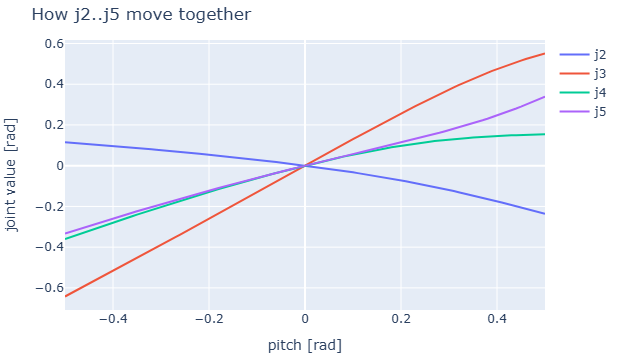

In [6]:
pitch_min, pitch_max = kh.pitch_range()
pitch_values = np.linspace(pitch_min, pitch_max, 101)        # [rad]
parallelogram = np.array([kh.parallelogram_joints(pitch) for pitch in pitch_values])

kh.plot_series(pitch_values, {"j2": parallelogram[:, 0], "j3": parallelogram[:, 1],
                              "j4": parallelogram[:, 2], "j5": parallelogram[:, 3]},
               xlabel="pitch [rad]", ylabel="joint value [rad]", title="How j2..j5 move together")

We write `rcm_joints(swing, pitch, insertion)`, which returns the six joint values `[j1, j2, j3, j4, j5, j6]` for the three reduced coordinates.

In [7]:
def rcm_joints(swing, pitch, insertion):
    # The six joint values for the reduced coordinates swing [rad], pitch [rad], insertion [m]
    j2, j3, j4, j5 = kh.parallelogram_joints(pitch)
    j1 = swing
    j6 = insertion
    return np.array([j1, j2, j3, j4, j5, j6])

> **T1.** Check it: move the robot through a combination of swing, pitch and insertion using `rcm_joints`, and record the RCM error and the force on the port. Both should stay close to zero. Note that pyBullet's `setJointMotorControlArray()` allows directly controlling position.

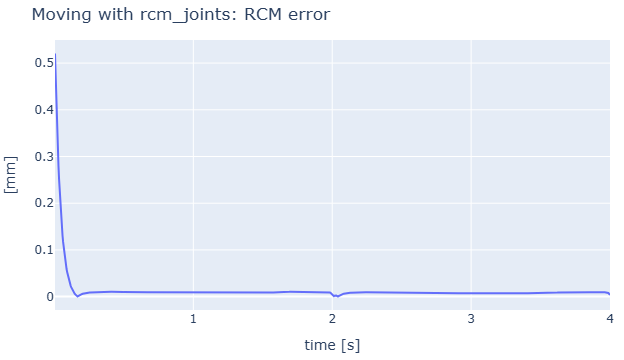

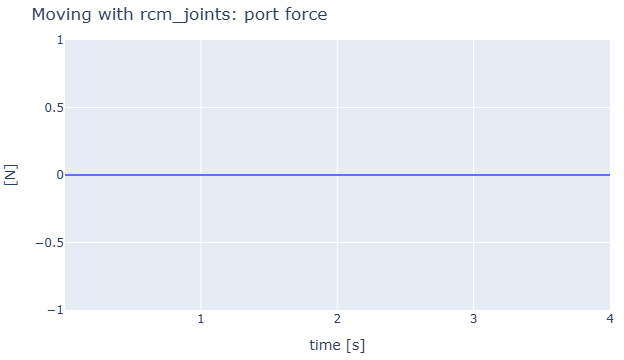

In [8]:
duration = 4.0       # [s]
t = 0.0
time_log, rcm_log, force_log = [], [], []


while t < duration:
    # SENSE
    error = rcm_error(robot)
    force = np.linalg.norm(kh.port_force(robot, port))

    # CONTROL: a slow motion in the three reduced coordinates    
    swing = 0.1 * np.sin(2*np.pi*0.25*t)
    pitch = 0.1 * np.sin(2*np.pi*0.25*t)
    insertion = 0.02 * np.sin(2*np.pi*0.25*t)
    
    q_target = rcm_joints(swing, pitch, insertion)

    # ACT
    p.setJointMotorControlArray(robot, joints, p.POSITION_CONTROL, targetPositions=q_target, forces=max_forces)
    p.stepSimulation()

    # WAIT
    time.sleep(DT)
    t = t + DT

    time_log.append(t)
    rcm_log.append(error * 1000)  # Convertido para mm
    force_log.append(force)


kh.plot_series(time_log, {"RCM error [mm]": rcm_log}, ylabel="[mm]", title="Moving with rcm_joints: RCM error")
kh.plot_series(time_log, {"force on the port [N]": force_log}, ylabel="[N]", title="Moving with rcm_joints: port force")


We create a `move_to` as a helper to control the joint positions:

In [9]:
def move_to(swing, pitch, insertion, steps):
    # Command the robot towards the reduced coordinates for a number of time steps
    q_target = rcm_joints(swing, pitch, insertion)
    for _ in range(steps):
        p.setJointMotorControlArray(robot, joints, p.POSITION_CONTROL, targetPositions=q_target, forces=max_forces)
        p.stepSimulation()

move_to(0.0, 0.0, 0.0, steps=240)     # back to HOME

## 4. The camera and the target

A camera is fixed to the instrument housing, to the side of the shaft, looking along it. `kh.get_camera_image(robot)` returns the colour image and a depth image.
It is a pinhole camera with intrinsic matrix $K$ (focal lengths $f_x, f_y$ and principal point $c_x, c_y$, in pixels):

K =
[[415.7   0.  320. ]
 [  0.  415.7 240. ]
 [  0.    0.    1. ]]


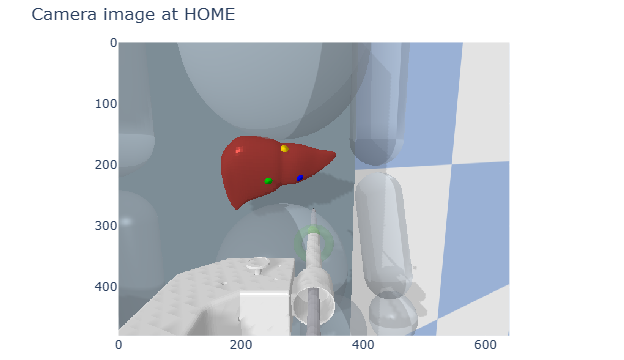

In [10]:
move_to(0.0, 0.0, 0.0, steps=240)     # back to HOME

K = kh.camera_matrix()
print("K =")
print(np.round(K, 1))

rgb, depth = kh.get_camera_image(robot)
kh.show_image(rgb, title="Camera image at HOME")

You can see the instrument shaft at the bottom, going through the trocar port (the ring), and the liver with the three dots.

`kh.find_dots(rgb)` finds the centre of each dot by selecting the pixels whose colour is clearly yellow, green or blue. It returns a $3 \times 2$ array with the pixel coordinates $(u, v)$ of the yellow, green and blue dots (a row is `nan` if that dot is not visible).

`kh.desired_dot_pixel(robot, colour)` returns where that dot **should** appear in the image when the instrument points straight at it, ready to be advanced.
The camera is to the side of the shaft, so this is not the centre of the image.

dots found [px]:
 [[271.7 174. ]
 [245.5 227. ]
 [296.9 221.8]]
blue target [px]: [320.  265.7]


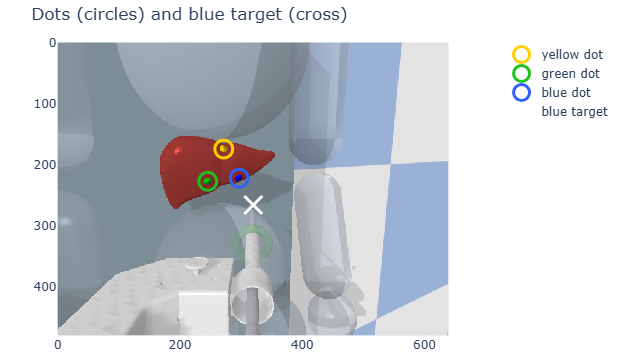

In [11]:
dots = kh.find_dots(rgb)                              # (3, 2) pixels: yellow, green, blue
blue = kh.DOT_COLOURS.index("blue")                   # row of the blue dot
blue_target = kh.desired_dot_pixel(robot, "blue")     # where it should be [px]

print("dots found [px]:\n", np.round(dots, 1))
print("blue target [px]:", np.round(blue_target, 1))
kh.show_image(rgb, title="Dots (circles) and blue target (cross)", dots=dots, targets={"blue": blue_target})

## 5. From the image error to the joints: the image Jacobian

![The image error](figures/image_error.png)

Our feature is the position of the blue dot in the image, $c = (u, v)$, and its target is $c^*$. The image error is

$$e = c - c^*$$

The instrument must point at the dot before it advances, so we align with swing and pitch only: two coordinates to move a 2D point in the image.
For small motions, the change of the dot in the image is linear in the change of swing and pitch:

$$\Delta c \approx J \begin{bmatrix} \Delta\psi \\ \Delta\varphi \end{bmatrix}, \qquad
J = \begin{bmatrix} \partial u / \partial \psi & \partial u / \partial \varphi \\ \partial v / \partial \psi & \partial v / \partial \varphi \end{bmatrix}$$

$J$ is the **image Jacobian** (in pixels per radian). We will not derive it: we **measure** it, by moving each coordinate a little and looking at how the dot moves in the image.

> **T2.** Estimate $J$ at HOME: take a picture, move the swing by a small $\delta$ and take another, come back, then do the same with the pitch. Each column of $J$ is the shift of the blue dot divided by $\delta$.

In [12]:
def dot_pixel(robot, colour):
    # Position of the dot of this colour in the image [px] (nan if not visible)
    rgb, _ = kh.get_camera_image(robot)
    dots = kh.find_dots(rgb)
    return dots[kh.DOT_COLOURS.index(colour)]


delta = 0.02          # small change of swing or pitch [rad]
settle_steps = 60     # time steps to let the robot reach each pose

# Go to start
move_to(0.0, 0.0, 0.0, settle_steps)
blue_home = dot_pixel(robot, "blue")

# Swing a bit (delta) and record blue pixel position
move_to(delta, 0.0, 0.0, settle_steps)
blue_swing = dot_pixel(robot, "blue")

move_to(0.0, 0.0, 0.0, settle_steps)

# Pitch a bit (delta) and record blue pixel position
move_to(0.0, delta, 0.0, settle_steps)
blue_pitch = dot_pixel(robot, "blue")

move_to(0.0, 0.0, 0.0, settle_steps)

# Fill in Jacobian (px/rad)
column_swing = (blue_swing - blue_home) / delta
column_pitch = (blue_pitch - blue_home) / delta
J = np.column_stack([column_swing, column_pitch])

print("J [px/rad] =")
print(np.round(J, 1))

J [px/rad] =
[[  20.6 -163.1]
 [-152.7    4.5]]


> **Q1.** Look at the numbers in $J$. Which coordinate moves the dot mostly up and down in the image, and which mostly left and right? Does it agree with where the camera is and how it is oriented?

**Q1 answer:** 
The swing coordinate moves the blue dot mainly up and down in the image, since it produces a larger change in the vertical coordinate (−152.7 px/rad). In contrast, pitch moves the dot mainly left and right, with a larger change in the horizontal coordinate (−163.1 px/rad).

These results agree with the camera's position and orientation, as the camera is mounted alongside the instrument shaft and observes the target from that perspective.

## 6. Visual servoing to the blue dot

To remove the error we invert the Jacobian: the change of swing and pitch that would cancel the error is $-J^{-1} e$. We use a gain $\lambda$  at each iteration (a proportional controller, now in the image), and repeat with a new picture:

$$\begin{bmatrix} \psi \\ \varphi \end{bmatrix} \leftarrow \begin{bmatrix} \psi \\ \varphi \end{bmatrix} - \lambda\, J^{-1} e$$

> **T3.** Write the visual servoing loop: at each iteration take a picture, find the blue dot, compute the error, update swing and pitch, and command the robot with `rcm_joints`. Stop when the error is below 1 pixel. Record the error and the force on the port.

Stopped after 8 iterations: swing = -0.289 rad, pitch = -0.147 rad


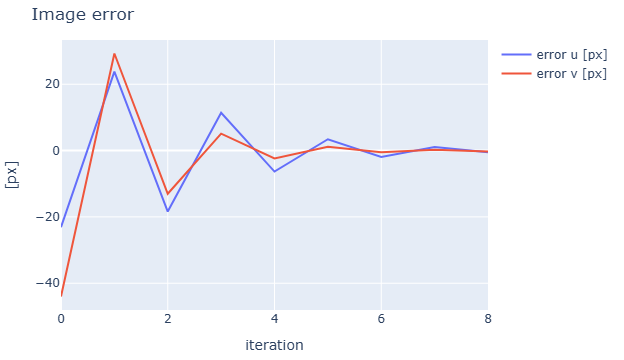

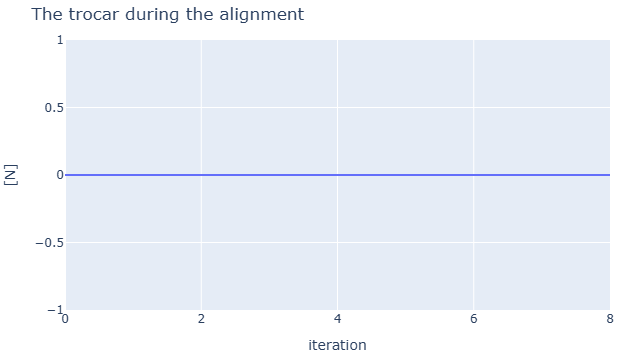

In [13]:
gain = 1.8              # fraction of the correction applied per iteration [-]
steps_per_iteration = 24   # time steps between pictures (0.1 s)
max_iterations = 60
tolerance = 1.0            # [px]

swing = 0.0
pitch = 0.0
insertion = 0.0
target = kh.desired_dot_pixel(robot, "blue", insertion)

iteration_log, error_u_log, error_v_log, force_log = [], [], [], []

move_to(0.0, 0.0, 0.0, 240)

for iteration in range(max_iterations):
    # Get blue dot position
    pixel = dot_pixel(robot, "blue")
    
    # Compute error in image
    image_error = pixel - target


    iteration_log.append(iteration)
    error_u_log.append(image_error[0])
    error_v_log.append(image_error[1])
    force_log.append(np.linalg.norm(kh.port_force(robot, port)))

    #If error is small, stop
    if np.linalg.norm(image_error) < tolerance:
        break

    # Use correction=np.linalg.solve(A,b) to solve A^-1*b
    correction = np.linalg.solve(J, image_error)
    swing = swing - gain * correction[0]
    pitch = pitch - gain * correction[1]

    move_to(swing, pitch, insertion, steps_per_iteration)

print(f"Stopped after {iteration} iterations: swing = {swing:.3f} rad, pitch = {pitch:.3f} rad")
kh.plot_series(iteration_log, {"error u [px]": error_u_log, "error v [px]": error_v_log},
               xlabel="iteration", ylabel="[px]", title="Image error")
kh.plot_series(iteration_log, {"force on the port [N]": force_log},
               xlabel="iteration", ylabel="[N]", title="The trocar during the alignment")

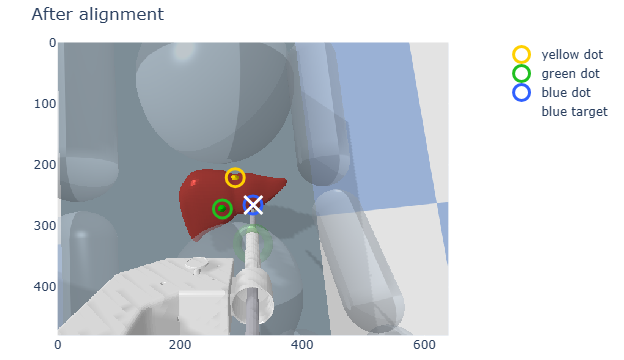

In [14]:
rgb, _ = kh.get_camera_image(robot)
kh.show_image(rgb, title="After alignment", dots=kh.find_dots(rgb),
              targets={"blue": kh.desired_dot_pixel(robot, "blue")})

> **Q2.** The Jacobian was measured at HOME, but used everywhere along the way. Why does the loop still converge? Try a larger gain (for example 1.0 and 1.8): what happens, and why?

**Q2 answer:**

The control loop still converges because the Jacobian measured at HOME remains a sufficiently accurate local approximation along the trajectory. Additionally, the feedback controller recalculates the image error at each iteration, allowing it to progressively correct the instrument's position.

With a gain of 0.3, convergence was smooth but slow, requiring 11 iterations. Increasing the gain to 1.0 reduced convergence to 3 iterations, with a small overshoot. However, with a gain of 1.8, the system exhibited larger oscillations around the target and required 8 iterations to converge. This occurs because the controller applies corrections that are too large, repeatedly overshooting the desired position.

## 7. Touching the liver

The instrument now points at the blue dot. Keeping swing and pitch fixed, we advance it with `j6`, half a millimetre at a time, and watch the force/torque sensor at the tip: as soon as the force goes above a small threshold, the tip is touching the liver and we stop.

> **T4.** Advance the instrument until the tip feels more than 1 N. Then print the force and torque measured at the tip, how far the tip is from the blue dot (`kh.dot_positions()` gives the 3D positions of the dots), and the force on the port.

In [17]:
dir(kh)

['BASE_POSITION',
 'COLLIDED',
 'DOT_ANGLES',
 'DOT_COLOURS',
 'DOT_DISTANCE',
 'DOT_RADIUS',
 'DOT_RGBA',
 'DT',
 'FAR',
 'FOV_Y_DEG',
 'G',
 'HOME',
 'IMAGE_HEIGHT',
 'IMAGE_WIDTH',
 'IN_COLAB',
 'JOINT_NAMES',
 'LIVER_DAMPING',
 'LIVER_DEPTH',
 'LIVER_FILE',
 'LIVER_SCALE',
 'LIVER_SHIFT',
 'LIVER_STIFFNESS',
 'NEAR',
 'PORT_FILE',
 'PORT_RADIUS',
 'PORT_TUBE_RADIUS',
 'RCM_POSITION',
 'SHAFT_DIRECTION_HOME',
 'TARGET_POSITION',
 '_COUPLING',
 '_DOT_POSITIONS',
 '_HERE',
 '_PLOT_COLOURS',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__spec__',
 '_aligned_coordinates',
 '_box',
 '_lab_file',
 '_matrix_to_quaternion',
 'add_patient',
 'add_scene',
 'camera_matrix',
 'connect',
 'desired_dot_pixel',
 'dot_positions',
 'find_dots',
 'get_camera_image',
 'get_joints',
 'go',
 'joint_index',
 'joint_indices',
 'joint_summary',
 'link_index',
 'link_pose',
 'load_robot',
 'np',
 'os',
 'p',
 'parallelogram_joints',
 'pitch_range',
 

In [19]:
contact_threshold = 1.0      # [N]
insertion_step = 0.0005      # [m]
steps_per_advance = 12       # time steps between checks (0.05 s)

insertion = 0.0
tip_force = np.zeros(3)
tip_torque = np.zeros(3)
#TODO: increment insertion until force while force is below threshold

while np.linalg.norm(tip_force) < contact_threshold:
    insertion = insertion + insertion_step
    move_to(swing, pitch, insertion, steps_per_advance)
    
    #wrench has forc and torque components
    wrench = kh.tip_wrench(robot)
    tip_force = wrench[:3]   # First 3 elements are force
    tip_torque = wrench[3:]  # Last 3 elements are torque

tip_position, _ = kh.link_pose(robot, "tool_tip_link")
blue_dot = kh.dot_positions()[blue]
distance_to_dot = np.linalg.norm(tip_position - blue_dot)        # [m]

print(f"Contact at j6 = {insertion * 1000:.1f} mm")
print(f"Force at the tip (tip frame):  {np.round(tip_force, 2)} N  (|F| = {np.linalg.norm(tip_force):.2f} N)")
print(f"Torque at the tip (tip frame): {np.round(tip_torque, 4)} N m")
print(f"Tip to blue dot: {distance_to_dot * 1000:.1f} mm,  force on the port: "
      f"{np.linalg.norm(kh.port_force(robot, port)):.2f} N")

Contact at j6 = 34.5 mm
Force at the tip (tip frame):  [[ 0.74  0.3   1.24]
 [ 0.   -0.   -0.  ]] N  (|F| = 1.48 N)
Torque at the tip (tip frame): [] N m
Tip to blue dot: 4.6 mm,  force on the port: 0.00 N


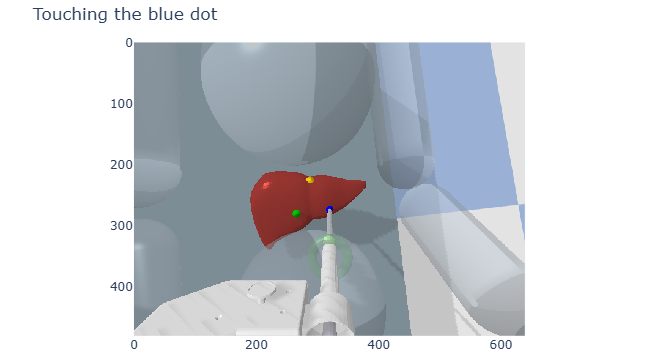

In [20]:
rgb, _ = kh.get_camera_image(robot)
kh.show_image(rgb, title="Touching the blue dot")

> **Q3.** The force at the tip is not only along the instrument ($z$): it also has $x$ and $y$ components. Why? What do they tell you about the liver surface at that point? And if the side of the shaft, further up, touched the liver, what would the tip sensor measure?

**Answer to Q3.**

The Liver is not a completely flat and perpendicular surface. Because of this, when the instrument tip presses against a curved, sloped, or soft organ surface, the reaction force pushes back perpendicularly (normal) to the local surface geometry. Unless the instrument hits the liver surface at precisely an 90 degree angle, the reaction force vector splits into all three axes ($x$, $y$ and $z$).

The $x$ and $y$ components will give information about the slope of the liver surface where the contact is happening. In other words, if these forces are large when compared to $z$ it means the instrument tip is hitting the liver at a sharpt angle.

If the side of the shaft touched the liver, then the tip sensor would measure zero force at the tip

## 8. Extra: the green and the yellow dots

Now visit the other two dots, in order: green, then yellow. For each one: pull the instrument back (`j6 = 0`, straight along its axis, so it does not drag on the liver), align with the dot using visual servoing (with the same $J$), and advance until contact.

> **T5.** Write `align_with(colour, swing, pitch)` and `touch_liver(swing, pitch)` from your code of sections 6 and 7, and use them to touch the green and then the yellow dot. For each dot, record the number of iterations, the contact force and the distance from the tip to the dot.

In [ ]:
def align_with(colour, swing, pitch, insertion=0.0):
    # Visual servoing until the dot of this colour is on its target; returns swing, pitch, iterations
    for iteration in range(max_iterations):
        target = kh.desired_dot_pixel(robot, colour, insertion)

        #TODO: add from section 6
        
        swing = swing - gain * correction[0]
        pitch = pitch - gain * correction[1]
        move_to(swing, pitch, insertion, steps_per_iteration)
    return swing, pitch, iteration


def touch_liver(swing, pitch):
    # Advance the instrument until the tip feels more than contact_threshold; returns insertion, force
    insertion = 0.0
    tip_force = np.zeros(3)
    #TODO: Add from section 7
    
    return insertion, tip_force


for colour in ["green", "yellow"]:
    move_to(swing, pitch, 0.0, steps=240)                      # pull back
    swing, pitch, iterations = align_with(colour, swing, pitch)
    insertion, tip_force = touch_liver(swing, pitch)

    tip_position, _ = kh.link_pose(robot, "tool_tip_link")
    dot = kh.dot_positions()[kh.DOT_COLOURS.index(colour)]
    print(f"{colour:5s}: {iterations} iterations, contact at j6 = {insertion * 1000:.1f} mm, "
          f"|F| = {np.linalg.norm(tip_force):.2f} N, tip to dot = {np.linalg.norm(tip_position - dot) * 1000:.1f} mm, "
          f"port force = {np.linalg.norm(kh.port_force(robot, port)):.2f} N")

## 9. Extra: sliding on the liver

Sometimes the instrument must stay in contact while it moves, for example to follow a line on the organ. What happens if we go from the blue dot to the green and the yellow without pulling back, keeping `j6` where it was when it touched the blue dot?

In [ ]:
move_to(swing, pitch, 0.0, steps=240)                          # pull back
swing, pitch, _ = align_with("blue", swing, pitch)
contact_insertion, _ = touch_liver(swing, pitch)               # touch the blue dot


def align_logging_force(colour, swing, pitch, insertion):
    # Like align_with, but also records the force at the tip at every time step
    force_log = []
    for iteration in range(max_iterations):
        target = kh.desired_dot_pixel(robot, colour, insertion)
        image_error = dot_pixel(robot, colour) - target
        if np.linalg.norm(image_error) < tolerance:
            break
        correction = np.linalg.solve(J, image_error)
        swing = swing - gain * correction[0]
        pitch = pitch - gain * correction[1]
        q_target = rcm_joints(swing, pitch, insertion)
        for _ in range(steps_per_iteration):
            p.setJointMotorControlArray(robot, joints, p.POSITION_CONTROL, targetPositions=q_target, forces=max_forces)
            p.stepSimulation()
            tip_force, _ = kh.tip_wrench(robot)
            force_log.append(np.linalg.norm(tip_force))
    return swing, pitch, force_log


swing, pitch, force_to_green = align_logging_force("green", swing, pitch, contact_insertion)
swing, pitch, force_to_yellow = align_logging_force("yellow", swing, pitch, contact_insertion)

position_force_log = force_to_green + force_to_yellow
kh.plot_series(np.arange(len(position_force_log)) * DT, {"force at the tip [N]": position_force_log},
               ylabel="[N]", title="Sliding with j6 in position control")
print(f"Largest force at the tip: {max(position_force_log):.1f} N")

The liver surface is not at the same distance from the trocar everywhere, so with `j6` fixed the tip digs in (or lifts off) as it moves: the force at the tip goes up to tens of newtons.
The swing and pitch are fine, the problem is the **insertion**. Instead of commanding a position for `j6`, we control the **force** along the instrument:

* `j6` is switched to torque control (its motor is released, and we send the force ourselves);
* the force we send compensates gravity along the instrument (`p.calculateInverseDynamics` with zero velocity and acceleration, as before), pushes with the desired contact force $F_d$, corrects the measured error with a small PI term, and is damped:

$$F_{j6} = g_6(q) + F_d + K_p (F_d - F_n) + K_i \int (F_d - F_n)\,dt - D\,\dot d$$

where $F_n$ is the force measured at the tip along the instrument (the $z$ component of `kh.tip_wrench`) and $\dot d$ is the velocity of `j6`. Without contact, the instrument moves forward at a speed of about $F_d / D$; in contact, it settles where the liver pushes back with $F_d$.

> **T6.** Write `force_control_step(swing, pitch)`, which does one time step with the swing and pitch in position control and `j6` in force control. Use it to touch the blue dot with $F_d = 2$ N, then slide to the green and the yellow dots while the visual servoing moves swing and pitch. Plot the force at the tip.

In [ ]:
desired_force = 2.0          # F_d [N]
force_kp = 0.5               # [-]
force_ki = 5.0               # [1/s]
integral_limit = 0.5         # anti-windup: largest value of the integral [N s]
damping = 40.0               # D [N s/m]

j6 = joints[5]
arm_joints = joints[:5]
force_error_integral = 0.0


def force_control_step(swing, pitch):
    # One time step: j1..j5 in position control (from swing, pitch), j6 in force control
    global force_error_integral
    q_target = rcm_joints(swing, pitch, 0.0)
    p.setJointMotorControlArray(robot, arm_joints, p.POSITION_CONTROL,
                                targetPositions=q_target[:5], forces=max_forces[:5])

    #TODO: get joint position and velocity 
    
    #TODO: Calculate gravity torque (force) with inverse dynamics
    #gravity = 

    tip_force, _ = kh.tip_wrench(robot)
    force_along_axis = tip_force[2]                                          # F_n [N]

    #TODO: Compute force error
    #force_error = 
    
    #Apply PID+Gravity to j6
    #j6_force = 

    p.setJointMotorControl2(robot, j6, p.TORQUE_CONTROL, force=j6_force)
    p.stepSimulation()
    return np.linalg.norm(tip_force)


def align_in_force_control(colour, swing, pitch, slow_gain=0.1):
    # Visual servoing with j6 in force control; slower gain, so the force loop can follow the surface
    force_log = []
    for iteration in range(150):
        insertion = p.getJointState(robot, j6)[0]
        target = kh.desired_dot_pixel(robot, colour, insertion)
        image_error = dot_pixel(robot, colour) - target
        if np.linalg.norm(image_error) < 1.5:
            break
        correction = np.linalg.solve(J, image_error)
        swing = swing - slow_gain * correction[0]
        pitch = pitch - slow_gain * correction[1]
        for _ in range(steps_per_iteration):
            force_log.append(force_control_step(swing, pitch))
    return swing, pitch, force_log


move_to(swing, pitch, 0.0, steps=240)                          # pull back
swing, pitch, _ = align_with("blue", swing, pitch)

p.setJointMotorControl2(robot, j6, p.VELOCITY_CONTROL, force=0)    # release the j6 motor
approach_log = [force_control_step(swing, pitch) for _ in range(480)]   # touch the blue dot (2 s)
swing, pitch, force_to_green = align_in_force_control("green", swing, pitch)
swing, pitch, force_to_yellow = align_in_force_control("yellow", swing, pitch)

force_control_log = approach_log + force_to_green + force_to_yellow
kh.plot_series(np.arange(len(force_control_log)) * DT, {"force at the tip [N]": force_control_log},
               ylabel="[N]", title="Sliding with j6 in force control")
print(f"Median force while sliding: {np.median(force_to_green + force_to_yellow):.2f} N, "
      f"95% of the time below {np.percentile(force_to_green + force_to_yellow, 95):.1f} N")
tip_position, _ = kh.link_pose(robot, "tool_tip_link")
print(f"Tip to yellow dot: {np.linalg.norm(tip_position - kh.dot_positions()[0]) * 1000:.1f} mm")

> **Q4.** Compare the two plots. Where do the remaining force peaks come from in force control? What would you change (gains, speed of the visual servoing) to make them smaller, and what would you lose?

In [ ]:
# give j6 back to position control, and pull the instrument out
p.setJointMotorControl2(robot, j6, p.POSITION_CONTROL, targetPosition=0.0, force=max_forces[5])
move_to(swing, pitch, 0.0, steps=240)

## 10. Questions for the report

> **Q5.** Go back to HOME and advance the instrument without aligning it first. Where does it touch the liver? What would happen in a real patient?
>
> **Q6.** The target pixels were computed from the known positions of the dots and a perfect camera model. In a real system, where would these come from, and what happens to the alignment if the camera is slightly rotated on the instrument?

## 11. Optional: estimating the Jacobian online

We measured $J$ once, at HOME, and used it for all three dots. That worked because $J$ changes little over the liver.
But suppose the camera  **rotated about its optical axis**: the image is rotated, and the $J$ we measured is wrong. 
Instead of keeping $J$ fixed, we can **correct it at every iteration** with what we observe. After each move we know the change of swing and pitch we commanded, $\Delta q$, and the change of the dot we then saw in the image, $\Delta c$. A good Jacobian should predict $\Delta c \approx J \Delta q$, so we correct $J$ by the prediction error, in the direction of the move (Broyden's update):

$$J \leftarrow J + \frac{(\Delta c - J\,\Delta q)\,\Delta q^T}{\Delta q^T \Delta q}$$

No extra probing moves are needed: the robot learns $J$ from the motions it makes anyway.

> **Q7 (optional).** From HOME, align with the blue dot twice, both starting with $J_{\text{wrong}}$: once keeping it fixed, and once correcting it with Broyden's update. Compare the image error over the iterations. 

In [ ]:
def servo_from_home(J_start, online_update, max_iterations=50):
    # Visual servoing to the blue dot from HOME, starting with the Jacobian J_start [px/rad]
    move_to(0.0, 0.0, 0.0, steps=240)
    J_estimate = J_start.copy()
    swing = 0.0
    pitch = 0.0
    target = kh.desired_dot_pixel(robot, "blue")
    previous_q = None
    previous_pixel = None
    error_log = []

    for iteration in range(max_iterations):
        pixel = dot_pixel(robot, "blue")
        if np.any(np.isnan(pixel)):
            print("  the dot left the image: stopped")
            break
        image_error = pixel - target
        error_log.append(np.linalg.norm(image_error))

        q_reduced = np.array([swing, pitch])
        if online_update and previous_q is not None:
            delta_q = q_reduced - previous_q             # [rad]
            delta_c = pixel - previous_pixel             # [px]
            prediction_error = delta_c - J_estimate @ delta_q
            #TODO: Estimate new Jacobian:
            #J_estimate = J_estimate + ...

        if np.linalg.norm(image_error) < tolerance:
            continue

        previous_q = q_reduced
        previous_pixel = pixel
        correction = np.linalg.solve(J_estimate, image_error)
        swing = swing - gain * correction[0]
        pitch = pitch - gain * correction[1]
        move_to(swing, pitch, 0.0, steps_per_iteration)

    print(f"  {len(error_log)} images, final error {error_log[-1]:.1f} px")
    return error_log


angle = np.radians(60)                    # the unknown rotation of the camera [rad]
camera_rotation = np.array([[np.cos(angle), -np.sin(angle)],
                            [np.sin(angle), np.cos(angle)]])
J_wrong = camera_rotation @ J

print("Fixed J_wrong:")
error_fixed = servo_from_home(J_wrong, online_update=False)
print("J_wrong corrected online (Broyden):")
error_online = servo_from_home(J_wrong, online_update=True)

kh.plot_series(list(range(len(error_fixed))), {"fixed J": error_fixed,"Broyden update": error_online}, xlabel="iteration",
               ylabel="image error [px]", title="Fixed Jacobian")
